In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import matplotlib.pyplot as plt
%matplotlib inline

import warnings
warnings.filterwarnings('ignore')

In [ ]:
from sklearn.datasets import fetch_openml

elec_data = fetch_openml(name='electricity', version=1)
elec_df = elec_data.frame

print("Data Shape:", elec_data.data.shape)
print("Features names:", elec_data.feature_names)
print("Target names:", elec_data.target_names)

Data Shape: (45312, 8)
Features names: ['date', 'day', 'period', 'nswprice', 'nswdemand', 'vicprice', 'vicdemand', 'transfer']
Target names: ['class']


Training samples: 33984
Testing samples: 11328
<class 'pandas.core.frame.DataFrame'>
Index: 33984 entries, 27325 to 27098
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   date       33984 non-null  float64 
 1   day        33984 non-null  category
 2   period     33984 non-null  float64 
 3   nswprice   33984 non-null  float64 
 4   nswdemand  33984 non-null  float64 
 5   vicprice   33984 non-null  float64 
 6   vicdemand  33984 non-null  float64 
 7   transfer   33984 non-null  float64 
 8   class      33984 non-null  category
dtypes: category(2), float64(7)
memory usage: 2.1 MB


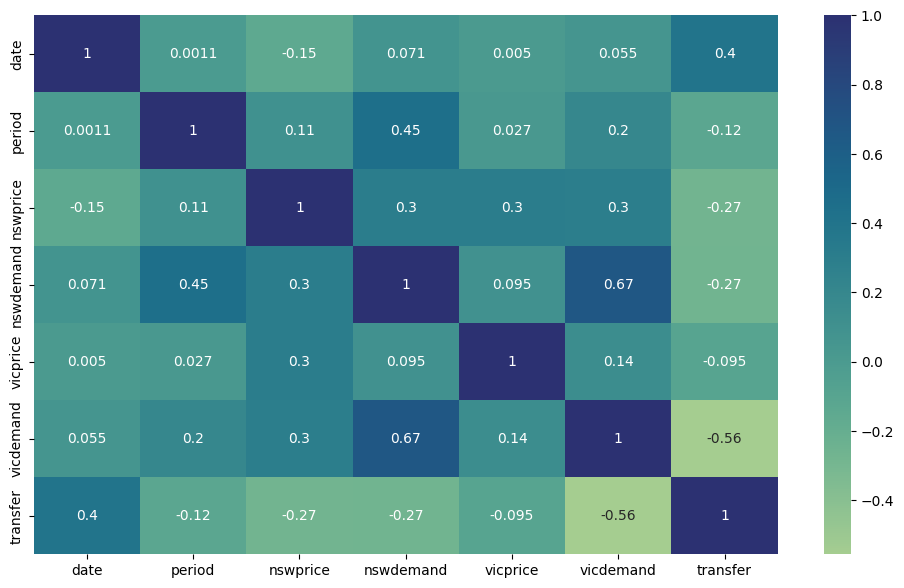

In [ ]:
from sklearn.model_selection import train_test_split

train_data, test_data = train_test_split(elec_df, test_size=0.25, random_state=20)

print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))

train_data.head(10)
train_data.info()
train_data.describe()
train_data.isnull().sum()

corr = train_data.corr(numeric_only = True)

plt.figure(figsize=(12, 7))
sns.heatmap(corr, annot=True, cmap = 'crest')
plt.show()

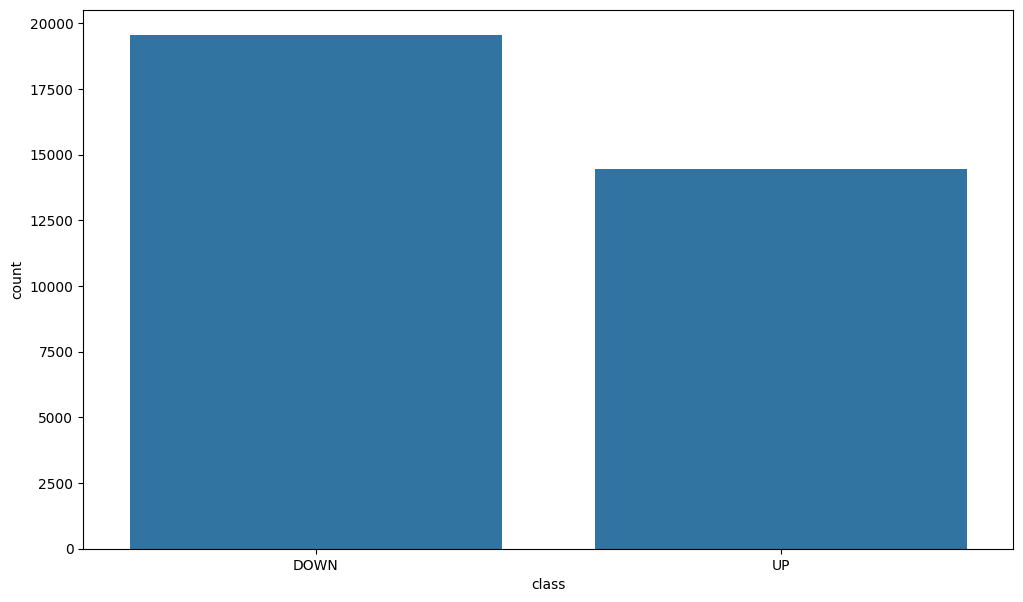

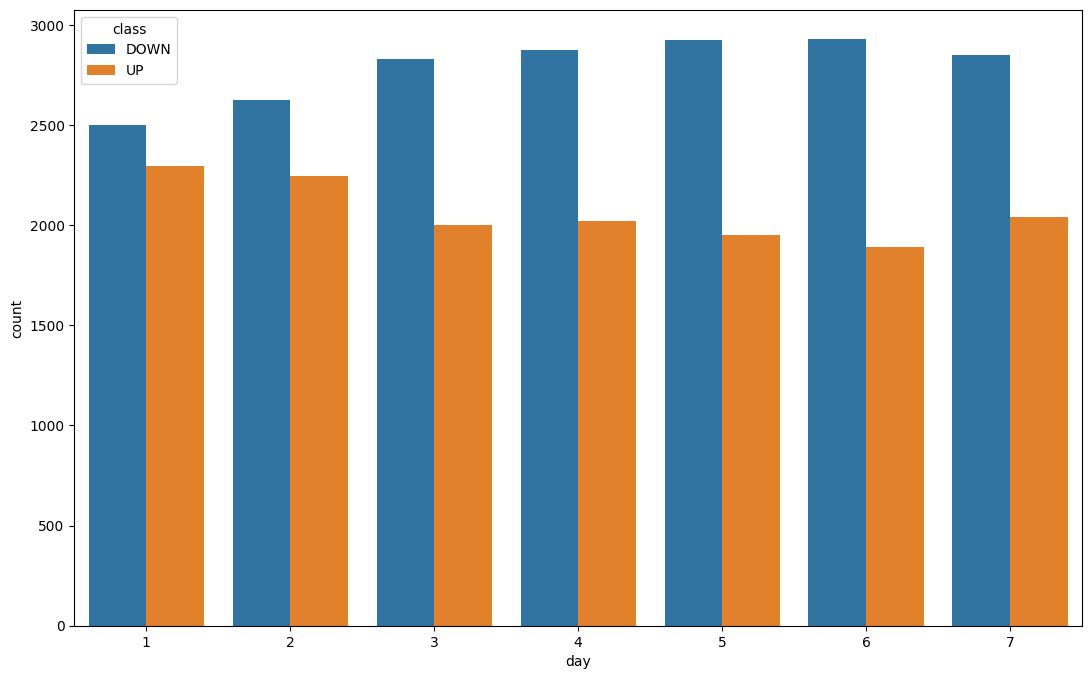

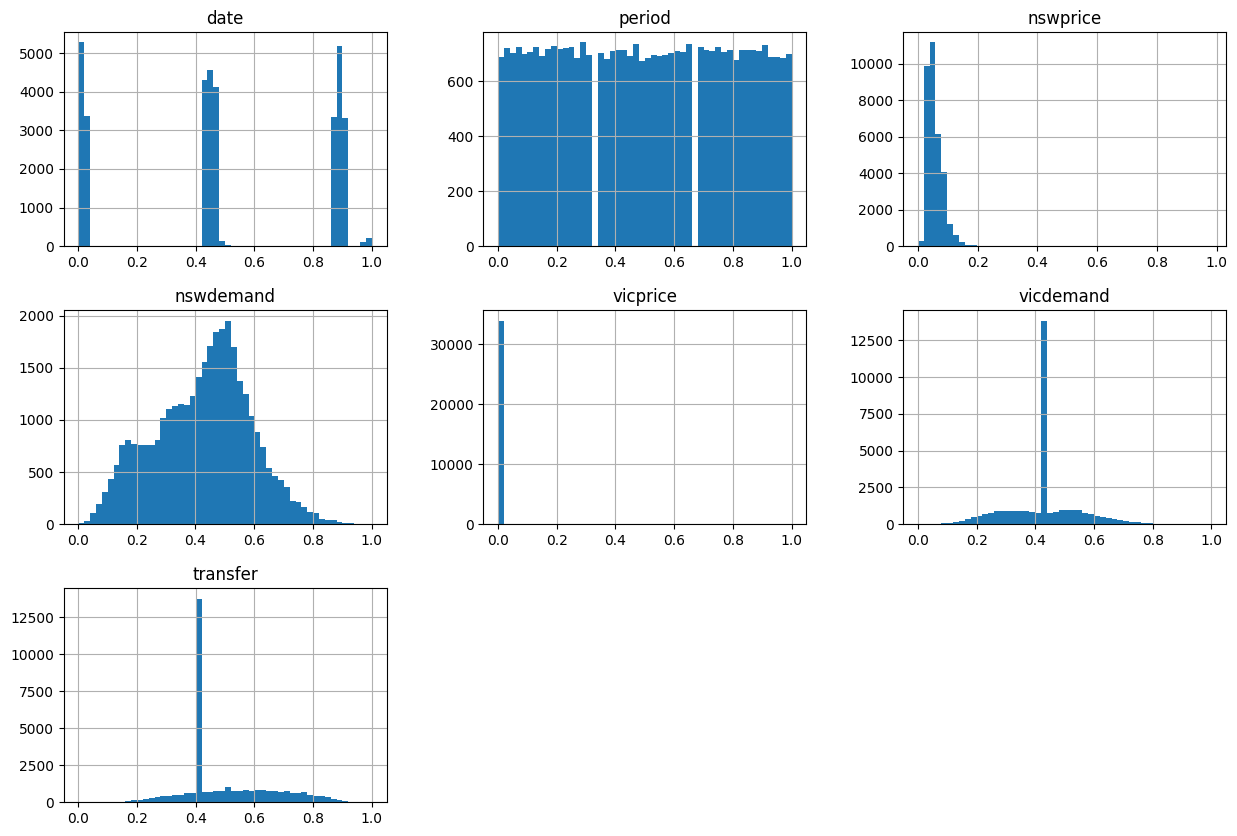

In [ ]:
plt.figure(figsize=(12, 7))
sns.countplot(data=train_data, x='class')
plt.show()

plt.figure(figsize=(13, 8))
sns.countplot(data=train_data, x='day', hue='class')
plt.show()

train_data.hist(bins=50, figsize=(15, 10))
plt.show()

In [ ]:
from sklearn.preprocessing import LabelEncoder

X_train = train_data.drop('class', axis=1)
y_train = train_data['class']

label_enc = LabelEncoder()
y_train_prepared = label_enc.fit_transform(y_train)

print(label_enc.classes_)

['DOWN' 'UP']


In [ ]:
from sklearn.metrics import accuracy_score

def accuracy(model, data, labels):
    predictions = model.predict(data)
    acc = accuracy_score(labels, predictions)

    return acc


**VOTING CODE**

In [ ]:
from sklearn.ensemble import VotingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

X_train_num = X_train.copy()
X_train_num['day'] = X_train_num['day'].astype(int)
models = [('lr', LogisticRegression(max_iter=100)),
          ('rf', RandomForestClassifier(n_estimators=10, random_state=42)),
          ('svc', SVC(probability=True, random_state=42))]

voting_hard = VotingClassifier(models, voting='hard')
voting_soft = VotingClassifier(models, voting='soft')
voting_hard.fit(X_train_num, y_train_prepared)
voting_soft.fit(X_train_num, y_train_prepared)
print(accuracy(voting_hard, X_train_num, y_train_prepared))
print(accuracy(voting_soft, X_train_num, y_train_prepared))


0.8170315442561206
0.9144303201506592


**BAGGING CLASSIFIER**

In [ ]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

bag_classifier = BaggingClassifier(
    DecisionTreeClassifier(class_weight='balanced'),
    max_samples=0.5, max_features=0.5, bootstrap=False
)

bag_classifier.fit(X_train, y_train_prepared)
print(accuracy(bag_classifier, X_train, y_train_prepared))


0.9824917608286252


**GRADIENT BOSTING**

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

grad_boost_clf = GradientBoostingClassifier(
    n_estimators=500,
    learning_rate=0.8,
    random_state=42,
    max_depth=2
)

grad_boost_clf.fit(X_train, y_train_prepared)
print(accuracy(grad_boost_clf, X_train, y_train_prepared))


0.9269362052730696


**ADA BOOST**

In [ ]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

adaboost_clf = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=3, class_weight='balanced'),
    n_estimators=300,
    learning_rate=0.5
)

adaboost_clf.fit(X_train, y_train_prepared)
print(accuracy(adaboost_clf, X_train, y_train_prepared))


0.7966395951035782


**XGBOOST**

In [ ]:
import xgboost as xgb

xgb_clf = xgb.XGBClassifier()
xgb_clf.fit(X_train_num, y_train_prepared)
print(accuracy(xgb_clf, X_train_num, y_train_prepared))

0.9439736346516008


**STACKING**

In [ ]:
from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

base_models = [
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
    ('dt', DecisionTreeClassifier(max_depth=5, random_state=42)),
    ('lr', LogisticRegression(max_iter=1000)),
]

stack_clf = StackingClassifier(
    estimators=base_models,
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5
)
stack_clf.fit(X_train_num, y_train_prepared)
print(accuracy(stack_clf, X_train_num, y_train_prepared))


1.0


EVALUATION

In [ ]:
X_test = test_data.drop('class', axis=1)
y_test = test_data['class']

y_test_prepared = label_enc.transform(y_test)

print(accuracy(grad_boost_clf, X_test, y_test_prepared))
print(accuracy(bag_classifier, X_test, y_test_prepared))


X_test_num = X_test.copy()
X_test_num['day'] = X_test_num['day'].astype(int)

print(accuracy(voting_hard, X_test_num, y_test_prepared))
print(accuracy(voting_soft, X_test_num, y_test_prepared))
print(accuracy(xgb_clf, X_test_num, y_test_prepared))
print(accuracy(stack_clf, X_test_num, y_test_prepared))
print(accuracy(adaboost_clf, X_test, y_test_prepared))





0.8968926553672316
0.8694385593220338
0.7974046610169492
0.845603813559322
0.9060734463276836
0.9073093220338984
0.7944915254237288
